# Tres maneras de partir los mismos 97 tiros: aleatoria, deduplicada y con campañas completas fuera

**Pregunta:** ¿Cuánto del conjunto de prueba de una partición aleatoria ya está en su conjunto de entrenamiento?

**Nivel 1: Fundamentos** · Requiere: 01-the-data/01-the-corpus-and-the-cases · Tiempo de lectura: unos 25 minutos

## Objetivos

Una predicción vale lo que puntúa en tiros que el modelo no ha visto, y qué tiros cuentan como no vistos depende de la partición. Este notebook cuenta, en los 97 tiros del corpus, lo que deja pasar una partición aleatoria y lo que quita cada partición más estricta.

Al terminar habrá:

- dibujado la partición aleatoria 80/20 que reporta la literatura y listado los tiros de prueba que tienen un gemelo idéntico en entrenamiento;
- repetido eso en 100 semillas para ver con qué frecuencia ocurre;
- encontrado los vectores de entradas duplicados del corpus y medido lo que quita una partición deduplicada y lo que conserva;
- construido las diez particiones con una campaña fuera y visto cómo la verificación de fuga rechaza una partición que pone una campaña en ambos lados.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

Una sola celda hace toda la preparación: importa los paquetes, imprime sus versiones instaladas para que la salida registre qué motor produjo cada número que sigue, define el ayudante de tablas y carga los 97 tiros de entrenamiento.

In [1]:
# Importaciones, las versiones detrás de cada número, un ayudante de tablas y el corpus
import json
from importlib.metadata import version
from pathlib import Path
from collections import Counter

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")


def show_table(columns, rows):
    # pandas no forma parte del entorno de notebooks, así que una tabla es una tabla HTML simple
    head = "".join(f"<th>{c}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


BENCHMARK = Path("../../../data/derived/benchmark.json")
train = bf.load_training_corpus()

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los 97 tiros | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| Los grupos duplicados versionados | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/benchmark.json`, campo `duplicate_groups` |

El protocolo aleatorio 80/20 es el que reportan los estudios de predictores aprendidos (Sui et al. 2025, https://doi.org/10.3390/app15031254). Aquí solo se usan las siete entradas de diseño y el tamaño medio medido de cada tiro; en este notebook no se ajusta ningún modelo.

## Método

Una partición es una `Split`: una tupla de entrenamiento, una de prueba, el nombre del protocolo y una nota. Dos propiedades deciden si una partición mide transferencia a un tiro nuevo.

1. **Ninguna fila en ambos lados.** Un tiro de prueba cuyas siete entradas son iguales a las de un tiro de entrenamiento, un gemelo, se memoriza y no se predice.
2. **Ninguna dependencia a través del corte.** Los tiros de una campaña comparten una masa rocosa, un equipo de perforación, un suministro de explosivo y un operador de medición, así que una partición aleatoria pone en entrenamiento casi-copias de cada tiro de prueba. Solo dejar fuera la campaña entera quita eso, y es también la pregunta que se hace un profesional: ¿qué tan bien se transfiere este modelo a mi mina? La validación cruzada que ignora la dependencia de los datos puede subestimar seriamente el error de predicción (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

El motor construye las particiones y verifica cada una con `assert_no_leakage`, que lanza un `LeakageError`. Qué mirar: cuántos gemelos trae una partición aleatoria, qué tiros son, y qué sigue compartido una vez que los gemelos se han ido.

### Paso 1: una partición aleatoria y sus gemelos

`random_split` baraja las filas con un generador con semilla y separa 20 por ciento como conjunto de prueba. La nota del motor cuenta las filas de prueba cuyas siete entradas son iguales a las de una fila de entrenamiento. La celda dibuja la semilla 0, indexa las filas de entrenamiento por sus entradas y lista, para cada tiro de prueba, el tiro de entrenamiento que duplica.

In [2]:
# Una partición aleatoria 80/20, y el gemelo en entrenamiento de cada tiro de prueba que lo tiene
split = bf.random_split(train, seed=0)
in_training = {}
for blast in split.train:
    in_training.setdefault(blast.features(), []).append(blast)
rows = []
for blast in split.test:
    for twin in in_training.get(blast.features(), []):
        rows.append((blast.blast_id, blast.site, blast.x50_m, twin.blast_id, twin.x50_m))
print(f"{split.protocol} | seed {split.seed} | {len(split.train)} entrenamiento, {len(split.test)} prueba")
print("nota del motor:", split.note)
show_table(["tiro de prueba", "campaña", "x50 medido (m)",
            "gemelo en entrenamiento", "x50 del gemelo (m)"], rows)

random-8020 | seed 0 | 78 entrenamiento, 19 prueba
nota del motor: 4 of 19 test rows share a feature vector with a training row


tiro de prueba,campaña,x50 medido (m),gemelo en entrenamiento,x50 del gemelo (m)
En12,Enusa,0.38,En11,0.31
En2,Enusa,0.37,En1,0.37
Sm3,Soma,0.23,Sm1,0.15
Sm3,Soma,0.23,Sm2,0.19
En3,Enusa,0.33,En5,0.46


La semilla 0 pone 78 tiros en entrenamiento y 19 en prueba, y 4 de esos 19 tiros de prueba tienen un gemelo: En12, En2, En3 y Sm3. La tabla muestra cuánto vale un gemelo para un modelo. En2 y En1 comparten sus entradas y su tamaño medido de 0,37 m, así que memorizar En1 responde a En2 con exactitud; En3 y En5 comparten entradas pero miden 0,33 m y 0,46 m, de modo que la respuesta memorizada se equivoca de forma apreciable, pero igual cae en la campaña correcta y en la escala correcta. La tabla no dice cuánto gana un modelo con esto, porque aquí no se ajusta ninguno; dice qué filas de prueba no son no vistas.

### Paso 2: con qué frecuencia

Una partición es una anécdota. La celda repite la partición en las semillas 0 a 99 con `repeated_random_splits`, cuenta los gemelos de cada una y dibuja su histograma.

medida,valor
particiones con al menos un gemelo,96 de 100
gemelos medios por partición,2.99 de 19
más gemelos en una partición,6
proporción media de la prueba que es gemela,15.7%


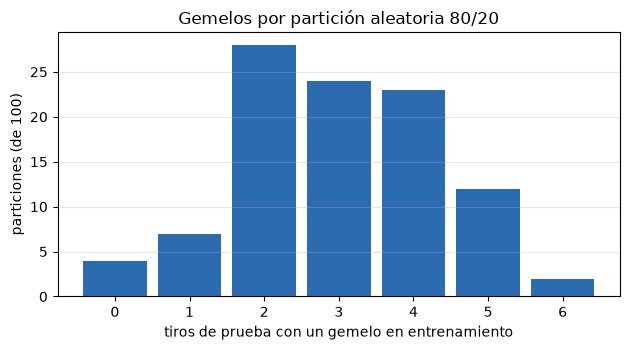

In [3]:
# El mismo conteo en 100 particiones con semilla
draws = bf.repeated_random_splits(train, n_repeats=100, seed=0)
twins = np.array([len(draw.detail["crossing_ids"]) for draw in draws])
test_size = len(draws[0].test)
rows = [
    ("particiones con al menos un gemelo", f"{int((twins > 0).sum())} de {len(twins)}"),
    ("gemelos medios por partición", f"{twins.mean():.2f} de {test_size}"),
    ("más gemelos en una partición", f"{twins.max()}"),
    ("proporción media de la prueba que es gemela", f"{twins.mean() / test_size:.1%}"),
]
show_table(["medida", "valor"], rows)

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.hist(twins, bins=np.arange(twins.max() + 2) - 0.5, color="#2b6cb0", rwidth=0.85)
ax.set_xlabel("tiros de prueba con un gemelo en entrenamiento")
ax.set_ylabel("particiones (de 100)")
ax.set_title("Gemelos por partición aleatoria 80/20")
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()

El histograma convierte la anécdota en una tasa: 96 de las 100 particiones contienen al menos un gemelo, la partición media tiene 2,99 gemelos entre sus 19 tiros de prueba, es decir 15,7 por ciento del conjunto de prueba, y la peor tiene 6. Una partición sin ningún gemelo es la excepción, no la regla. La figura no muestra cómo crecería la cuenta con una proporción de prueba mayor, y cuenta solo tiros cuyas siete entradas son exactamente iguales, de modo que los casi-gemelos que difieren en el tercer decimal no están en ella: el 15,7 por ciento es un piso de lo que deja pasar una partición aleatoria.

### Paso 3: de dónde vienen los gemelos

Algunos tiros de una campaña se dispararon con el mismo diseño, así que sus siete entradas son idénticas y solo difiere el tamaño medido. `duplicate_groups` los encuentra. La celda tabula cada grupo con su campaña y la dispersión de sus tamaños medidos.

In [4]:
# Los grupos de tiros que comparten un vector de entradas, con sus tamaños medidos
groups = bf.duplicate_groups(train)
by_id = {blast.blast_id: blast for blast in train}
rows = []
for group in groups:
    sizes = [by_id[blast_id].x50_m for blast_id in group]
    rows.append((", ".join(group), by_id[group[0]].site, len(group), min(sizes), max(sizes)))
show_table(["tiros", "campaña", "tamaño del grupo", "x50 menor (m)",
            "x50 mayor (m)"], rows)
print(f"grupos: {len(groups)} | filas involucradas: {sum(len(group) for group in groups)}")

tiros,campaña,tamaño del grupo,x50 menor (m),x50 mayor (m)
"En1, En2",Enusa,2,0.37,0.37
"En11, En12",Enusa,2,0.31,0.38
"En3, En5",Enusa,2,0.33,0.46
"En8, En9",Enusa,2,0.26,0.42
"Mr1, Mr3",Mrica,2,0.13,0.17
"Sm1, Sm2, Sm3",Soma,3,0.15,0.23
"Sm4, Sm5, Sm6, Sm7",Soma,4,0.22,0.28


grupos: 7 | filas involucradas: 17


Hay 7 grupos y 17 filas involucradas, todas en tres campañas: cuatro grupos en Enusa, uno en Mrica y dos en Soma, con tamaños de 2 a 4. Un grupo es un diseño disparado más de una vez, y los tamaños medidos dentro de un grupo difieren: En8 y En9 van de 0,26 m a 0,42 m, y los cuatro tiros de Soma del último grupo de 0,22 m a 0,28 m. Entradas idénticas no significan entonces resultados idénticos, que es la razón por la que la partición deduplicada promedia un grupo y no descarta todos sus miembros salvo uno.

### Paso 4: la partición deduplicada

`deduplicated_split` primero colapsa cada grupo en un representante cuyo tamaño medido es el promedio del grupo, y luego parte. Promediar es una decisión declarada: las entradas duplicadas llevan dispersión real de medición, y una fila por diseño distinto es lo que se le debe pedir predecir a un modelo. La celda dibuja una partición, la repite en 100 semillas y cuenta los gemelos que quedan.

In [5]:
# Una partición deduplicada: ningún vector de entradas cruza el corte, en 100 particiones
dedup = bf.deduplicated_split(train, seed=0)
print(dedup.protocol, f"| {len(dedup.train)} entrenamiento, {len(dedup.test)} prueba")
print("nota del motor:", dedup.note)
dedup_draws = bf.repeated_deduplicated_splits(train, n_repeats=100, seed=0)
twins_dedup = []
for draw in dedup_draws:
    seen = {blast.features() for blast in draw.train}
    twins_dedup.append(sum(1 for blast in draw.test if blast.features() in seen))
rows = [
    ("aleatoria 80/20", f"{twins.mean():.2f}", f"{twins.max()}"),
    ("deduplicada", f"{np.mean(twins_dedup):.2f}", f"{max(twins_dedup)}"),
]
show_table(["protocolo", "gemelos medios por partición", "máximo en una partición"], rows)

dedup-random | 70 entrenamiento, 17 prueba
nota del motor: 97 rows collapsed to 87 distinct feature vectors before splitting


protocolo,gemelos medios por partición,máximo en una partición
aleatoria 80/20,2.99,6
deduplicada,0.00,0


El motor colapsa las 97 filas en 87 vectores de entradas distintos y parte esos, lo que deja 70 para entrenamiento y 17 para prueba. En 100 particiones el número medio de gemelos baja de 2,99 a 0,00 y el mayor de 6 a 0, de modo que la primera propiedad de una buena partición, ninguna fila en ambos lados, se cumple ahora en cada partición. La tabla no dice que la partición esté limpia: quita las entradas idénticas, y los tiros de una campaña que difieren en una sola entrada siguen en ambos lados. El paso siguiente lo mide.

### Paso 5: una campaña fuera

`leave_one_site_out` entrega una partición por campaña: esa campaña es la prueba y las otras nueve son entrenamiento. La celda lista los diez pliegues, luego construye una partición que no es válida, todo el corpus como entrenamiento y Enusa como prueba, y muestra cómo `assert_no_leakage` la rechaza.

In [6]:
# Los diez pliegues, y una partición inválida que la verificación de fuga debe rechazar
folds = list(bf.leave_one_site_out(train))
rows = [(f.detail["held_out_site"], len(f.test), len(f.train), f.detail["n_sites_in_train"]) for f in folds]
show_table(["campaña fuera", "prueba", "entrenamiento", "campañas en entrenamiento"], rows)

enusa = tuple(blast for blast in train if blast.site == "Enusa")
invalid = bf.Split(protocol="leave-out-Enusa", train=tuple(train), test=enusa, seed=None, note="", detail={})
try:
    bf.splits.assert_no_leakage(invalid, allow_duplicate_features=False)
except bf.LeakageError as refusal:
    print("rechazada:", str(refusal)[:100], "...")

campaña fuera,prueba,entrenamiento,campañas en entrenamiento
Akdaglar,22,75,9
Dongri-Buzurg,9,88,9
Enusa,12,85,9
Miami,6,91,9
Mrica,11,86,9
Murgul,7,90,9
Ozmert,7,90,9
Reocin,10,87,9
Reocin-UG,6,91,9
Soma,7,90,9


rechazada: leave-out-Enusa: 12 blast(s) on both sides: ['En1', 'En10', 'En11', 'En12', 'En2', 'En3', 'En4', 'En ...


Los diez pliegues tienen entre 6 y 22 tiros de prueba, Miami y Reocin-UG en el extremo pequeño y Akdaglar con 22, y cada pliegue entrena con exactamente 9 campañas. El rechazo del motor nombra el problema en una línea: la partición inválida pone 12 tiros en ambos lados, todos los de Enusa, y `assert_no_leakage` la detiene antes de que se pudiera puntuar algún modelo. La tabla no dice que los pliegues sean comparables en dificultad; un pliegue de 6 tiros y uno de 22 dan puntajes de precisión muy distinta, lo que los notebooks siguientes tienen en cuenta.

### Paso 6: la dependencia que deja la deduplicación

Quitar los gemelos no quita la campaña compartida. Para cada tiro de prueba de las 100 particiones deduplicadas, la celda cuenta los tiros de entrenamiento que provienen de su propia campaña, promedia por campaña, y lo contrapone al cero de los pliegues con una campaña fuera. El número entre paréntesis en cada etiqueta es el tamaño de la campaña.

campaña,tiros,"tiros de entrenamiento de la misma campaña, por tiro de prueba"
Akdaglar,22,16.9
Dongri-Buzurg,9,6.6
Enusa,12,5.6
Miami,6,4.1
Mrica,11,7.3
Murgul,7,4.7
Ozmert,7,4.9
Reocin,10,7.4
Reocin-UG,6,4.2
Soma,7,0.8


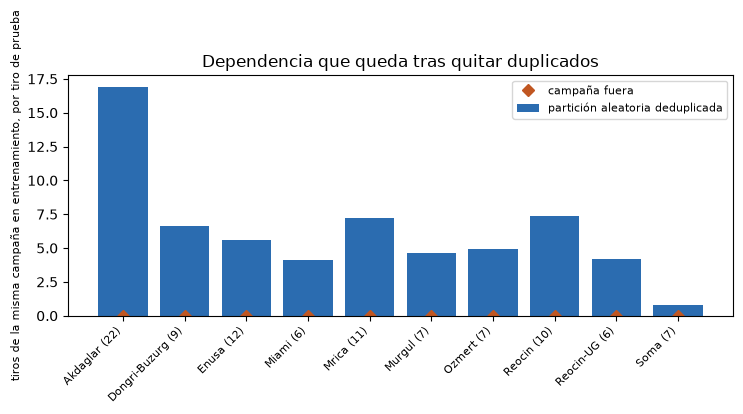

In [7]:
# Lo que una partición aleatoria deduplicada aún da a cada tiro de prueba: tiros de entrenamiento de su propia campaña
campaigns = sorted({blast.site for blast in train})
mates = {campaign: [] for campaign in campaigns}
for draw in dedup_draws:
    in_training_by_campaign = Counter(blast.site for blast in draw.train)
    for blast in draw.test:
        mates[blast.site].append(in_training_by_campaign[blast.site])
averages = [np.mean(mates[campaign]) for campaign in campaigns]
sizes = Counter(blast.site for blast in train)
rows = [(campaign, sizes[campaign], f"{average:.1f}") for campaign, average in zip(campaigns, averages)]
show_table(["campaña", "tiros", "tiros de entrenamiento de la misma campaña, por tiro de prueba"], rows)

fig, ax = plt.subplots(figsize=(7.4, 3.8))
position = np.arange(len(campaigns))
ax.bar(position, averages, color="#2b6cb0", label="partición aleatoria deduplicada")
ax.plot(position, np.zeros(len(campaigns)), "D", color="#c05621", label="campaña fuera")
labels = [f"{campaign} ({sizes[campaign]})" for campaign in campaigns]
ax.set_xticks(position, labels, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("tiros de la misma campaña en entrenamiento, por tiro de prueba", fontsize=8)
ax.set_title("Dependencia que queda tras quitar duplicados")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Sin gemelos, una partición aleatoria igual le entrega a cada tiro de prueba muchos tiros de su propia campaña: en promedio 16,9 para Akdaglar, 7,4 para Reocin, 7,3 para Mrica y 5,6 para Enusa, y el más bajo, Soma con 0,8, es bajo solo porque sus siete tiros colapsan en pocos diseños distintos. Son los tiros que comparten una masa rocosa, un equipo de perforación y un suministro de explosivo con el tiro de prueba, y las marcas en cero muestran que dejar la campaña fuera los quita todos. La figura cuenta campaña compartida y no información compartida, así que no dice cuánto aprovecha un modelo de ella; dice que la segunda propiedad de una buena partición no la cumple ninguna partición aleatoria.

### Verificación contra el benchmark versionado

La única comparación con un artefacto versionado en este notebook: los grupos duplicados encontrados aquí deben ser los que la ejecución offline escribió en `benchmark.json`.

In [8]:
# Verificación: los grupos duplicados son iguales a los que versionó la ejecución offline
committed_groups = json.loads(BENCHMARK.read_text(encoding="utf-8"))["duplicate_groups"]
found_groups = sorted(map(sorted, bf.duplicate_groups(train)))
print("mismos grupos que el benchmark versionado:", found_groups == sorted(map(sorted, committed_groups)))

mismos grupos que el benchmark versionado: True


## Resultados

**Respuesta:** una partición aleatoria 80/20 de estos 97 tiros tiene unos 3 de sus 19 tiros de prueba ya en entrenamiento. En la primera partición son 4 de 19, en 100 particiones 96 contienen al menos un gemelo, la media es 2,99 por partición, que es 15,7 por ciento del conjunto de prueba, y la peor tiene 6. Los gemelos vienen de 7 grupos de 17 tiros que repiten un diseño dentro de Enusa, Mrica y Soma. Una partición deduplicada quita todo gemelo (0,00 por partición, 0 como máximo) pero deja a cada tiro de prueba entre 0,8 y 16,9 tiros de su propia campaña en entrenamiento, y solo dejar la campaña fuera lo lleva a cero.

**Lo que esto no muestra.** Aquí no se puntúa ningún modelo, así que el notebook no dice cuánto se infla un puntaje por gemelos o por compañeros de campaña; el notebook siguiente define el puntaje, y el notebook de nivel 3 mide la brecha en un ensamble publicado. La cuenta de gemelos además cubre solo la igualdad exacta de las siete entradas, y los diez pliegues son de tamaño muy desigual, de 6 a 22 tiros.

## Resumen

- Una partición aleatoria 80/20 filtra: 96 de 100 particiones llevan al menos un tiro de prueba con un vector de entradas idéntico en entrenamiento, 2,99 en promedio.
- Deduplicar quita los gemelos pero no la campaña compartida; solo dejar fuera una campaña completa no deja ningún tiro de prueba con un compañero de campaña en entrenamiento.
- El motor cuenta la fuga y rechaza una partición inválida con una campaña fuera antes de puntuar cualquier modelo.
- Siguiente: el notebook 02 define el puntaje, el modelo nulo y el intervalo para una campaña fuera.

## Referencias

- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (validación cruzada con datos dependientes)
- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (el protocolo aleatorio 80/20 de los estudios de predictores aprendidos)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/